# TTC Bus Delay — Exploratory Data Analysis

Input: `data/interim/merged.parquet` (cleaned TTC bus delay incidents, 2018-2024,
left-joined with hourly Toronto weather). This notebook explores the target
variable, time patterns, incident types, routes/locations, direction, weather
relationships, a leakage check on `min_gap`, and a drift preview comparing
early vs. late years. Every figure is saved to `reports/figures/` as it is
produced.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "merged.parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

FINDINGS = {}  # collects computed numbers for docs/eda_findings.md

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_ROOT)}")

df = pd.read_parquet(DATA_PATH)
df.shape

(382131, 16)

## A. Dataset overview

Shape, dtypes, missing values per column, date range, and the number of
unique routes, locations, incident types and vehicles.

In [2]:
print("shape:", df.shape)
print()
print(df.dtypes)
print()
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"missing": missing, "missing_pct": missing_pct})
missing_table = missing_table[missing_table["missing"] > 0].sort_values("missing", ascending=False)
print(missing_table)

FINDINGS["n_rows"] = int(len(df))
FINDINGS["n_cols"] = int(df.shape[1])
FINDINGS["date_min"] = str(df["timestamp"].min())
FINDINGS["date_max"] = str(df["timestamp"].max())
FINDINGS["n_routes"] = int(df["route"].nunique())
FINDINGS["n_locations"] = int(df["location"].nunique())
FINDINGS["n_incident_types"] = int(df["incident"].nunique())
FINDINGS["n_vehicles"] = int(df["vehicle"].nunique())
FINDINGS["missing_location_pct"] = float(missing_pct.get("location", 0.0))
FINDINGS["missing_incident_pct"] = float(missing_pct.get("incident", 0.0))
FINDINGS["missing_min_gap_pct"] = float(missing_pct.get("min_gap", 0.0))
FINDINGS["missing_vehicle_pct"] = float(missing_pct.get("vehicle", 0.0))

print()
print(f"date range: {FINDINGS['date_min']} to {FINDINGS['date_max']}")
print(f"unique routes: {FINDINGS['n_routes']}, locations: {FINDINGS['n_locations']}, "
      f"incident types: {FINDINGS['n_incident_types']}, vehicles: {FINDINGS['n_vehicles']}")

shape: (382131, 16)

date                               datetime64[us]
route                                      string
time                                       string
day                                        string
location                                   string
incident                                   string
min_delay                                 float64
min_gap                                   float64
direction                                  string
vehicle                                   float64
timestamp         datetime64[us, America/Toronto]
temperature_2m                            float64
precipitation                             float64
rain                                      float64
snowfall                                  float64
wind_speed_10m                            float64
dtype: object

          missing  missing_pct
vehicle     25815         6.76
incident      935         0.24
min_gap       530         0.14
location      292         0.08

date ran

saved reports/figures/01_missing_values.png


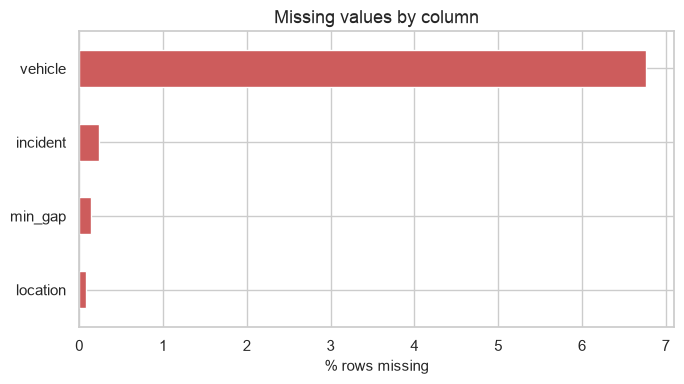

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
missing_table["missing_pct"].sort_values().plot.barh(ax=ax, color="indianred")
ax.set_xlabel("% rows missing")
ax.set_ylabel("")
ax.set_title("Missing values by column")
fig.tight_layout()
save_fig(fig, "01_missing_values.png")
plt.show()

## B. Target distribution (`min_delay`)

Histogram on a linear and a log scale, percentiles, and the share of
zero-minute delays (kept in the data per `params.yaml: drop_zero_delay: false`).

In [4]:
pctiles = df["min_delay"].quantile([0.50, 0.75, 0.90, 0.95, 0.99])
zero_share = float((df["min_delay"] == 0).mean() * 100)

FINDINGS["delay_median"] = float(pctiles.loc[0.50])
FINDINGS["delay_p75"] = float(pctiles.loc[0.75])
FINDINGS["delay_p90"] = float(pctiles.loc[0.90])
FINDINGS["delay_p95"] = float(pctiles.loc[0.95])
FINDINGS["delay_p99"] = float(pctiles.loc[0.99])
FINDINGS["delay_mean"] = float(df["min_delay"].mean())
FINDINGS["zero_delay_pct"] = zero_share

print(pctiles)
print(f"mean: {FINDINGS['delay_mean']:.2f}")
print(f"zero-minute delays: {zero_share:.2f}% of rows")

0.50     10.0
0.75     18.0
0.90     28.0
0.95     30.0
0.99    137.0
Name: min_delay, dtype: float64
mean: 16.22
zero-minute delays: 4.67% of rows


saved reports/figures/02_target_distribution.png


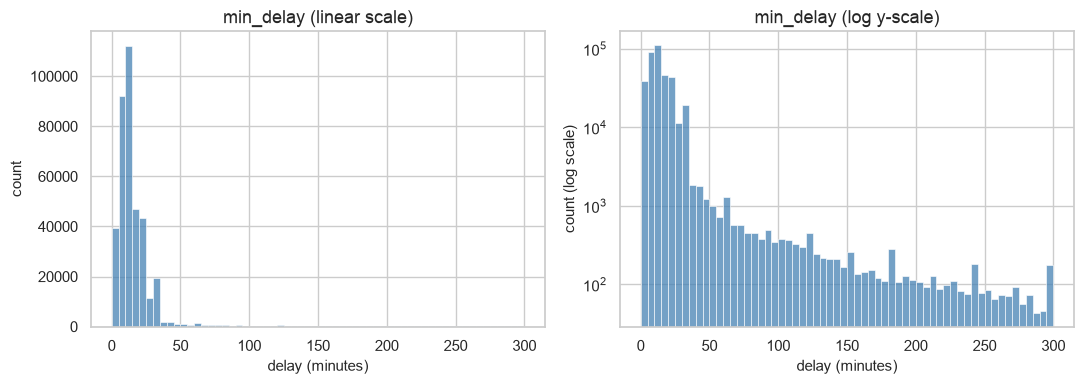

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["min_delay"], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("min_delay (linear scale)")
axes[0].set_xlabel("delay (minutes)")
axes[0].set_ylabel("count")

sns.histplot(df["min_delay"], bins=60, ax=axes[1], color="steelblue")
axes[1].set_yscale("log")
axes[1].set_title("min_delay (log y-scale)")
axes[1].set_xlabel("delay (minutes)")
axes[1].set_ylabel("count (log scale)")

fig.tight_layout()
save_fig(fig, "02_target_distribution.png")
plt.show()

## C. Time patterns

Incident count and mean delay by hour of day, by day of week, a heatmap of
mean delay by hour x day of week, by month, and by year (2020 is expected to
show a dip from reduced COVID-era service).

saved reports/figures/03_by_hour.png


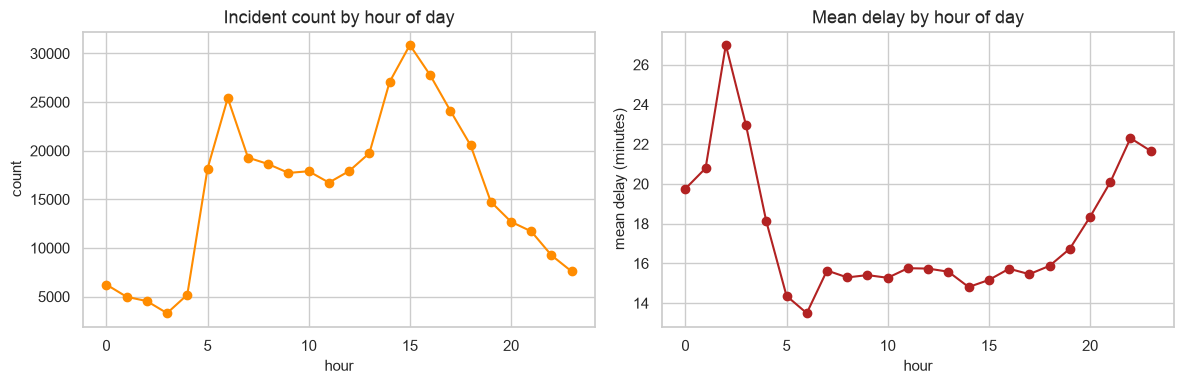

In [6]:
df["hour"] = df["timestamp"].dt.hour
df["dow"] = df["timestamp"].dt.dayofweek  # Monday=0
df["dow_name"] = df["timestamp"].dt.day_name()
df["month"] = df["timestamp"].dt.month
df["year"] = df["timestamp"].dt.year

by_hour = df.groupby("hour")["min_delay"].agg(["count", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_hour["count"].plot(ax=axes[0], marker="o", color="darkorange")
axes[0].set_title("Incident count by hour of day")
axes[0].set_xlabel("hour")
axes[0].set_ylabel("count")

by_hour["mean"].plot(ax=axes[1], marker="o", color="firebrick")
axes[1].set_title("Mean delay by hour of day")
axes[1].set_xlabel("hour")
axes[1].set_ylabel("mean delay (minutes)")

fig.tight_layout()
save_fig(fig, "03_by_hour.png")
plt.show()

FINDINGS["peak_incident_hour"] = int(by_hour["count"].idxmax())
FINDINGS["peak_delay_hour"] = int(by_hour["mean"].idxmax())
FINDINGS["peak_delay_hour_value"] = float(by_hour["mean"].max())

saved reports/figures/04_by_day_of_week.png


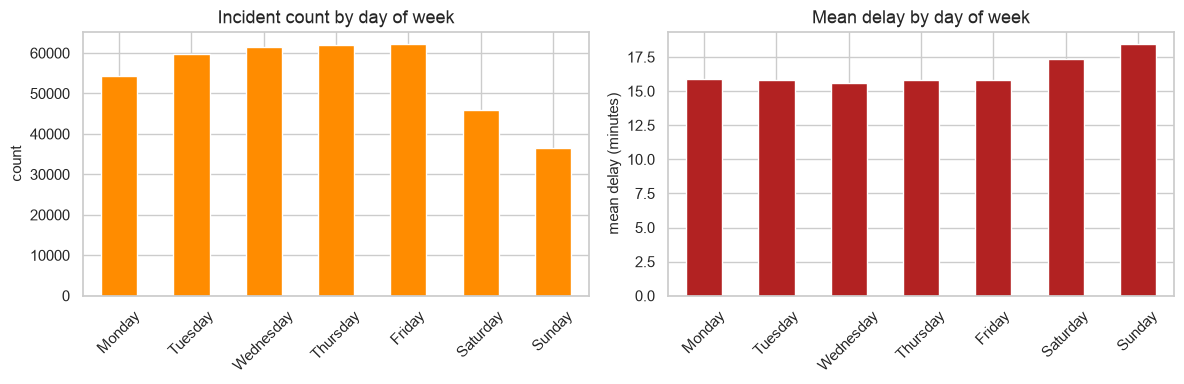

In [7]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_dow = df.groupby("dow_name")["min_delay"].agg(["count", "mean"]).reindex(dow_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_dow["count"].plot(ax=axes[0], kind="bar", color="darkorange")
axes[0].set_title("Incident count by day of week")
axes[0].set_xlabel("")
axes[0].set_ylabel("count")
axes[0].tick_params(axis="x", rotation=45)

by_dow["mean"].plot(ax=axes[1], kind="bar", color="firebrick")
axes[1].set_title("Mean delay by day of week")
axes[1].set_xlabel("")
axes[1].set_ylabel("mean delay (minutes)")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
save_fig(fig, "04_by_day_of_week.png")
plt.show()

FINDINGS["weekend_mean_delay"] = float(df.loc[df["dow"] >= 5, "min_delay"].mean())
FINDINGS["weekday_mean_delay"] = float(df.loc[df["dow"] < 5, "min_delay"].mean())

saved reports/figures/05_heatmap_hour_dow.png


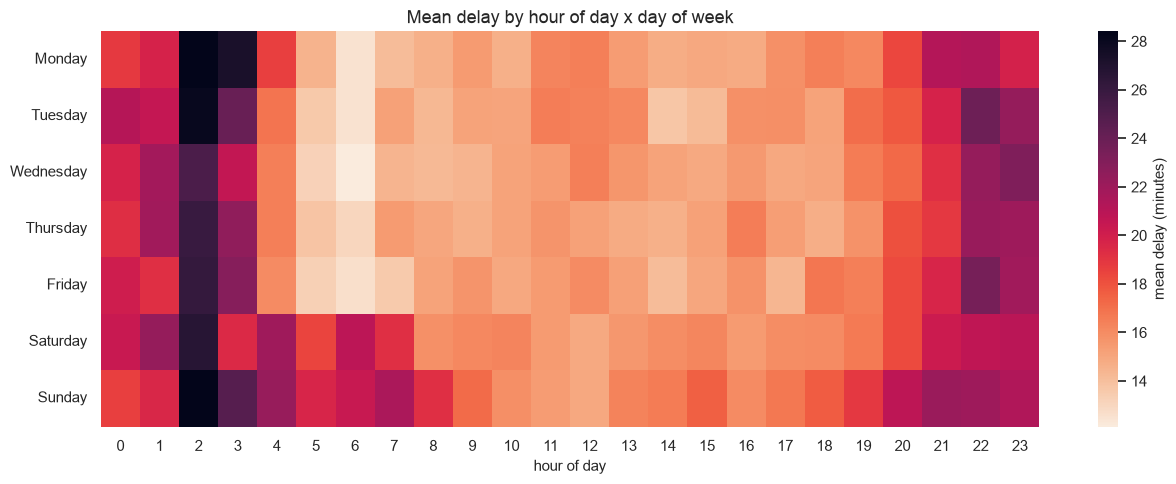

In [8]:
pivot = df.pivot_table(index="dow_name", columns="hour", values="min_delay", aggfunc="mean").reindex(dow_order)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pivot, cmap="rocket_r", ax=ax, cbar_kws={"label": "mean delay (minutes)"})
ax.set_title("Mean delay by hour of day x day of week")
ax.set_xlabel("hour of day")
ax.set_ylabel("")
fig.tight_layout()
save_fig(fig, "05_heatmap_hour_dow.png")
plt.show()

saved reports/figures/06_by_month.png


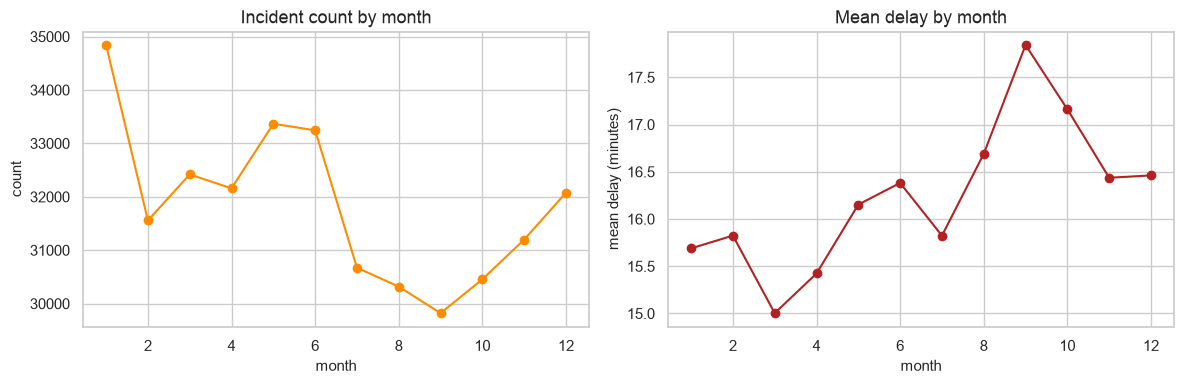

In [9]:
by_month = df.groupby("month")["min_delay"].agg(["count", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_month["count"].plot(ax=axes[0], marker="o", color="darkorange")
axes[0].set_title("Incident count by month")
axes[0].set_xlabel("month")
axes[0].set_ylabel("count")

by_month["mean"].plot(ax=axes[1], marker="o", color="firebrick")
axes[1].set_title("Mean delay by month")
axes[1].set_xlabel("month")
axes[1].set_ylabel("mean delay (minutes)")

fig.tight_layout()
save_fig(fig, "06_by_month.png")
plt.show()

      count       mean
year                  
2018  72417  14.664747
2019  61471  15.646467
2020  35633  15.795807
2021  41645  16.633545
2022  57575  16.968459
2023  55070  17.051425
2024  58320  17.207390


saved reports/figures/07_by_year.png


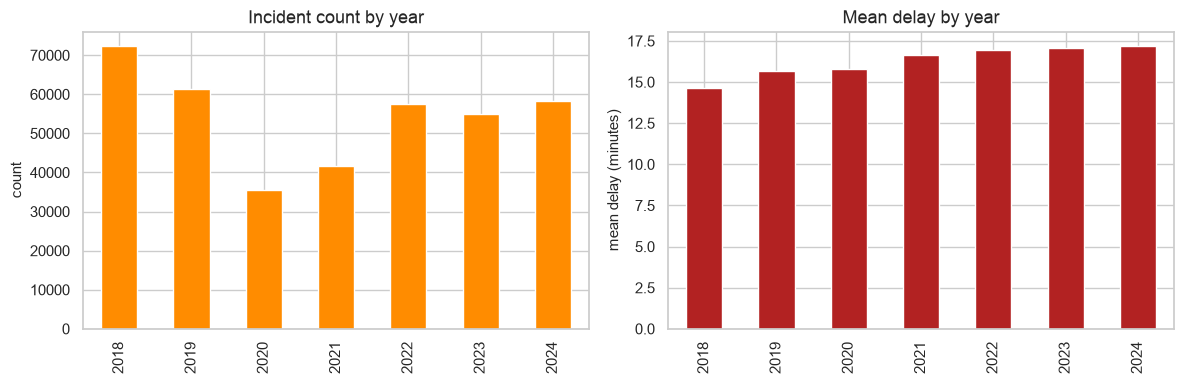

In [10]:
by_year = df.groupby("year")["min_delay"].agg(["count", "mean"])
print(by_year)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_year["count"].plot(ax=axes[0], kind="bar", color="darkorange")
axes[0].set_title("Incident count by year")
axes[0].set_xlabel("")
axes[0].set_ylabel("count")

by_year["mean"].plot(ax=axes[1], kind="bar", color="firebrick")
axes[1].set_title("Mean delay by year")
axes[1].set_xlabel("")
axes[1].set_ylabel("mean delay (minutes)")

fig.tight_layout()
save_fig(fig, "07_by_year.png")
plt.show()

FINDINGS["year_2020_count"] = int(by_year.loc[2020, "count"])
FINDINGS["year_2019_count"] = int(by_year.loc[2019, "count"])
FINDINGS["year_2020_drop_pct"] = float((1 - by_year.loc[2020, "count"] / by_year.loc[2019, "count"]) * 100)
FINDINGS["year_2020_mean_delay"] = float(by_year.loc[2020, "mean"])
FINDINGS["year_counts"] = {int(k): int(v) for k, v in by_year["count"].items()}

## D. Incident types

Top incident types by count, and the (different) ranking by mean delay,
each as a horizontal bar chart.

saved reports/figures/08_incident_types.png


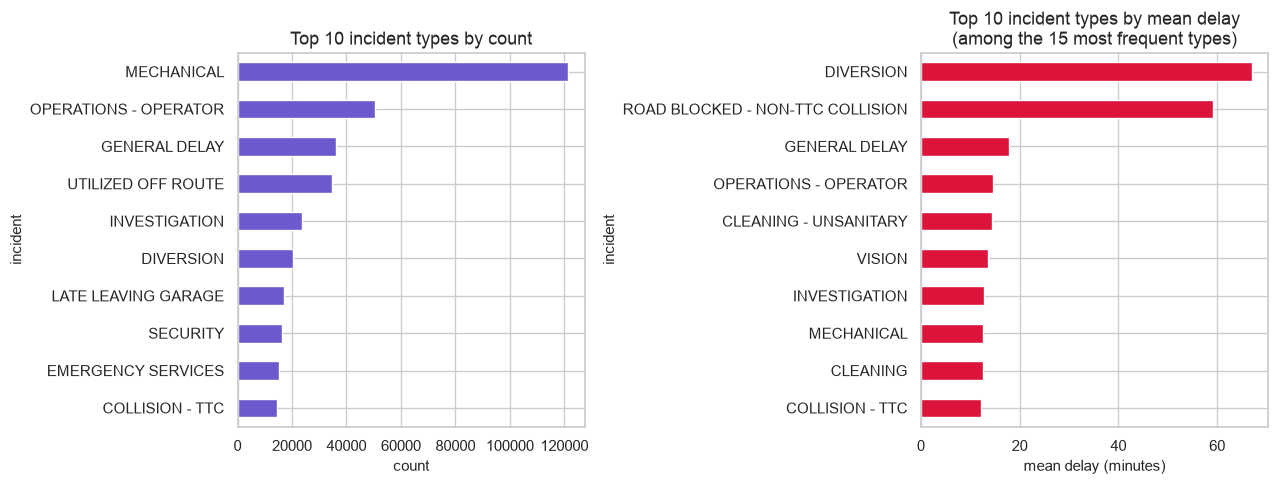

In [11]:
top_count = df["incident"].value_counts().head(10)
top_delay = df.groupby("incident")["min_delay"].mean().loc[df["incident"].value_counts().head(15).index].sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_count.sort_values().plot.barh(ax=axes[0], color="slateblue")
axes[0].set_title("Top 10 incident types by count")
axes[0].set_xlabel("count")

top_delay.sort_values().plot.barh(ax=axes[1], color="crimson")
axes[1].set_title("Top 10 incident types by mean delay\n(among the 15 most frequent types)")
axes[1].set_xlabel("mean delay (minutes)")

fig.tight_layout()
save_fig(fig, "08_incident_types.png")
plt.show()

FINDINGS["top_incident_by_count"] = str(top_count.index[0])
FINDINGS["top_incident_by_count_n"] = int(top_count.iloc[0])
FINDINGS["top_incident_by_count_share_pct"] = float(top_count.iloc[0] / len(df) * 100)
FINDINGS["top_incident_by_delay"] = str(top_delay.index[0])
FINDINGS["top_incident_by_delay_value"] = float(top_delay.iloc[0])

## E. Routes and locations

Top 15 routes by incident count and their mean delay, plus how many distinct
locations there are and how many of them appear fewer than 10 times (this
decides whether/how to group rare locations before modelling).

saved reports/figures/09_top_routes.png


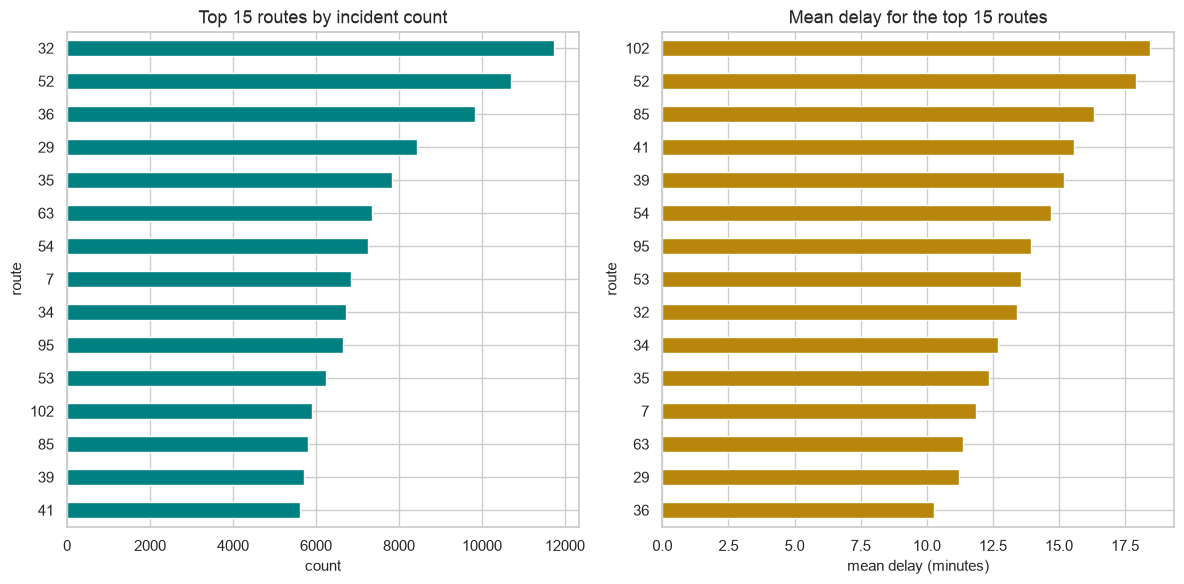

In [12]:
top_routes = df["route"].value_counts().head(15)
route_delay = df.groupby("route")["min_delay"].mean().loc[top_routes.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
top_routes.sort_values().plot.barh(ax=axes[0], color="teal")
axes[0].set_title("Top 15 routes by incident count")
axes[0].set_xlabel("count")

route_delay.sort_values().plot.barh(ax=axes[1], color="darkgoldenrod")
axes[1].set_title("Mean delay for the top 15 routes")
axes[1].set_xlabel("mean delay (minutes)")

fig.tight_layout()
save_fig(fig, "09_top_routes.png")
plt.show()

FINDINGS["top_route"] = str(top_routes.index[0])
FINDINGS["top_route_count"] = int(top_routes.iloc[0])

unique locations: 58640
locations with fewer than 10 occurrences: 54726 (93.3% of locations, 23.27% of rows)


saved reports/figures/10_location_frequency.png


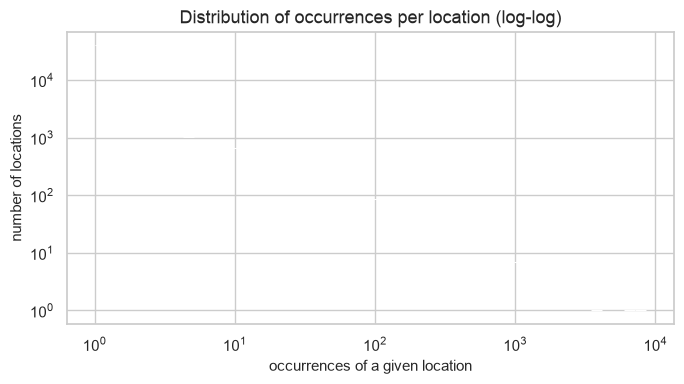

In [13]:
loc_counts = df["location"].value_counts()
n_locations = len(loc_counts)
n_rare = int((loc_counts < 10).sum())
rare_share_of_locations = n_rare / n_locations * 100
rare_share_of_rows = loc_counts[loc_counts < 10].sum() / len(df) * 100

print(f"unique locations: {n_locations}")
print(f"locations with fewer than 10 occurrences: {n_rare} ({rare_share_of_locations:.1f}% of locations, "
      f"{rare_share_of_rows:.2f}% of rows)")

FINDINGS["n_locations_check"] = int(n_locations)
FINDINGS["n_rare_locations"] = n_rare
FINDINGS["rare_locations_pct_of_locations"] = float(rare_share_of_locations)
FINDINGS["rare_locations_pct_of_rows"] = float(rare_share_of_rows)

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(loc_counts, bins=50, log_scale=(True, True), ax=ax, color="teal")
ax.set_title("Distribution of occurrences per location (log-log)")
ax.set_xlabel("occurrences of a given location")
ax.set_ylabel("number of locations")
fig.tight_layout()
save_fig(fig, "10_location_frequency.png")
plt.show()

## F. Direction

Counts per direction (including `UNKNOWN`, produced by `normalise_direction`
for anything that doesn't map cleanly to N/S/E/W/B) and mean delay per
direction.

           count       mean
direction                  
N          84783  15.273144
S          79423  15.227478
E          77222  15.362979
W          71049  15.517235
UNKNOWN    68807  19.633032
B            847  64.703660


saved reports/figures/11_direction.png


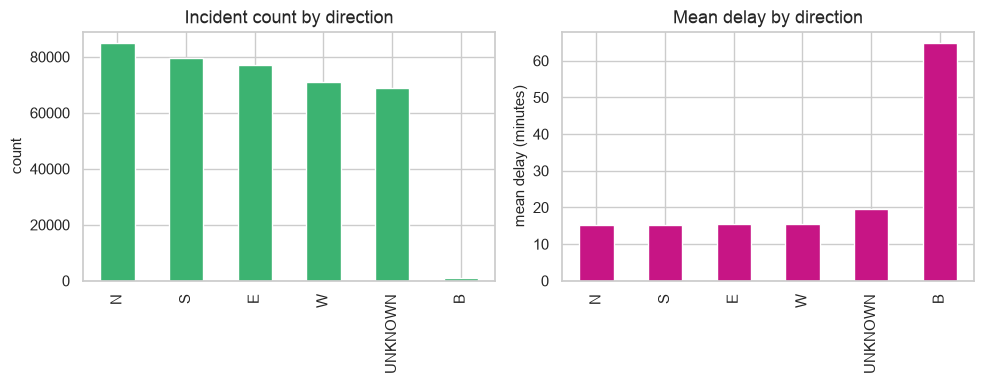

In [14]:
dir_stats = df.groupby("direction")["min_delay"].agg(["count", "mean"]).sort_values("count", ascending=False)
print(dir_stats)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
dir_stats["count"].plot.bar(ax=axes[0], color="mediumseagreen")
axes[0].set_title("Incident count by direction")
axes[0].set_xlabel("")
axes[0].set_ylabel("count")

dir_stats["mean"].plot.bar(ax=axes[1], color="mediumvioletred")
axes[1].set_title("Mean delay by direction")
axes[1].set_xlabel("")
axes[1].set_ylabel("mean delay (minutes)")

fig.tight_layout()
save_fig(fig, "11_direction.png")
plt.show()

FINDINGS["unknown_direction_pct"] = float(dir_stats.loc["UNKNOWN", "count"] / len(df) * 100)
FINDINGS["direction_counts"] = {str(k): int(v) for k, v in dir_stats["count"].items()}

## G. Weather

Mean delay by precipitation bins (none / light / heavy), by snowfall
(none vs. any), and by temperature bins.

                  count       mean
precipitation                     
none             310878  16.215821
light (<=2.5mm)   67237  16.184749
heavy (>2.5mm)     4016  17.305030

               count       mean
any snowfall   19017  16.589157
no snowfall   363114  16.202562

                 count       mean
temperature_2m                   
< -10C           11555  15.310948
-10 to 0C        66028  15.783683
0 to 10C        120762  16.048873
10 to 20C        99426  16.949249
> 20C            84360  16.079659


saved reports/figures/12_weather.png


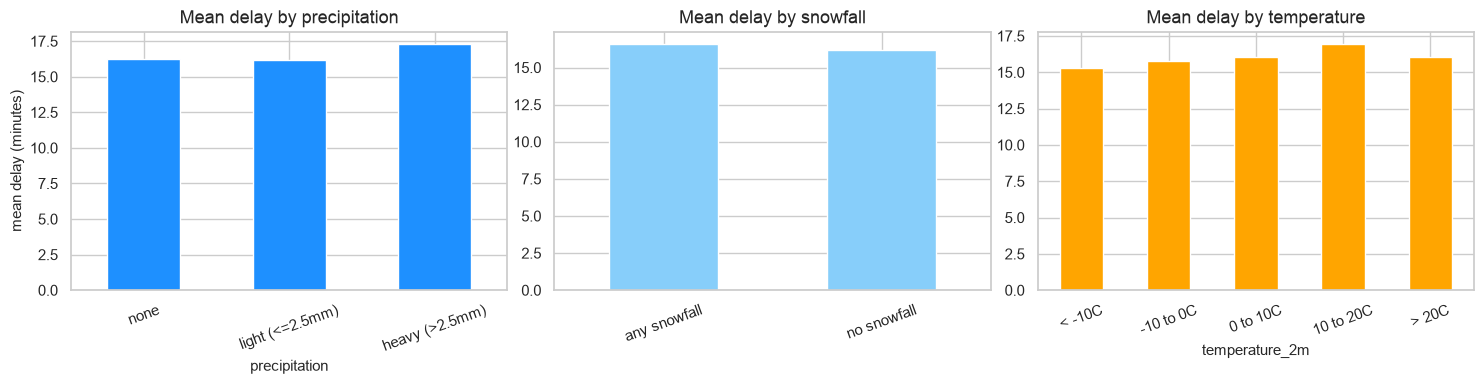

In [15]:
precip_bins = pd.cut(
    df["precipitation"], bins=[-0.01, 0, 2.5, np.inf], labels=["none", "light (<=2.5mm)", "heavy (>2.5mm)"]
)
precip_stats = df.groupby(precip_bins)["min_delay"].agg(["count", "mean"])

snow_bins = np.where(df["snowfall"] > 0, "any snowfall", "no snowfall")
snow_stats = df.groupby(snow_bins)["min_delay"].agg(["count", "mean"])

temp_bins = pd.cut(
    df["temperature_2m"],
    bins=[-np.inf, -10, 0, 10, 20, np.inf],
    labels=["< -10C", "-10 to 0C", "0 to 10C", "10 to 20C", "> 20C"],
)
temp_stats = df.groupby(temp_bins)["min_delay"].agg(["count", "mean"])

print(precip_stats)
print()
print(snow_stats)
print()
print(temp_stats)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
precip_stats["mean"].plot.bar(ax=axes[0], color="dodgerblue")
axes[0].set_title("Mean delay by precipitation")
axes[0].set_ylabel("mean delay (minutes)")
axes[0].tick_params(axis="x", rotation=20)

snow_stats["mean"].plot.bar(ax=axes[1], color="lightskyblue")
axes[1].set_title("Mean delay by snowfall")
axes[1].tick_params(axis="x", rotation=20)

temp_stats["mean"].plot.bar(ax=axes[2], color="orange")
axes[2].set_title("Mean delay by temperature")
axes[2].tick_params(axis="x", rotation=20)

fig.tight_layout()
save_fig(fig, "12_weather.png")
plt.show()

FINDINGS["delay_no_precip"] = float(precip_stats.loc["none", "mean"])
FINDINGS["delay_heavy_precip"] = float(precip_stats.loc["heavy (>2.5mm)", "mean"])
FINDINGS["delay_no_snow"] = float(snow_stats.loc["no snowfall", "mean"])
FINDINGS["delay_any_snow"] = float(snow_stats.loc["any snowfall", "mean"])

## H. Leakage check: `min_gap`

`min_gap` is the gap until the *next* scheduled vehicle, which TTC only
finalises once the disrupted trip has actually been handled — i.e. it is
recorded *after* the incident's delay is already known, making it leak the
target at prediction time. We confirm this with the correlation and a
scatter plot.

corr(min_delay, min_gap) = 0.882 (n=381,601)


saved reports/figures/13_min_gap_leakage.png


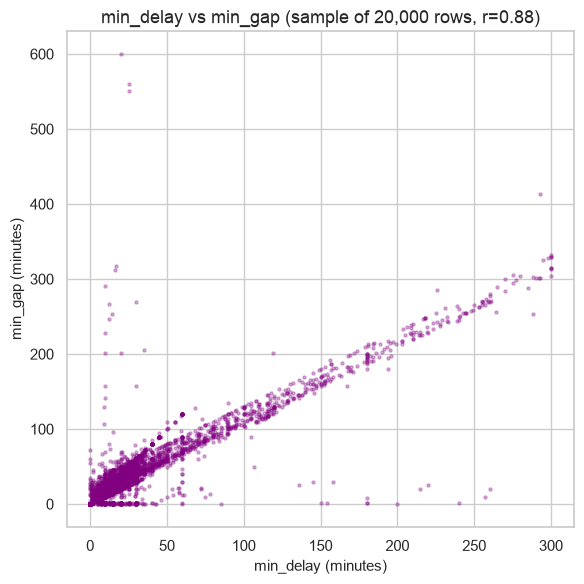

In [16]:
pair = df[["min_delay", "min_gap"]].dropna()
corr = pair["min_delay"].corr(pair["min_gap"])
print(f"corr(min_delay, min_gap) = {corr:.3f} (n={len(pair):,})")

FINDINGS["min_gap_corr"] = float(corr)
FINDINGS["min_gap_pair_n"] = int(len(pair))

sample = pair.sample(n=20_000, random_state=0)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sample["min_delay"], sample["min_gap"], s=5, alpha=0.3, color="purple")
ax.set_xlabel("min_delay (minutes)")
ax.set_ylabel("min_gap (minutes)")
ax.set_title(f"min_delay vs min_gap (sample of {len(sample):,} rows, r={corr:.2f})")
fig.tight_layout()
save_fig(fig, "13_min_gap_leakage.png")
plt.show()

## I. Drift preview: 2018-2019 vs 2023-2024

Compares the distribution of `min_delay` and the incident-type mix between
the earliest two years and the latest two years in the data.

2018-2019: n=133,888, mean=15.12, median=10.00
2023-2024: n=113,390, mean=17.13, median=11.00


saved reports/figures/14_drift_delay_distribution.png


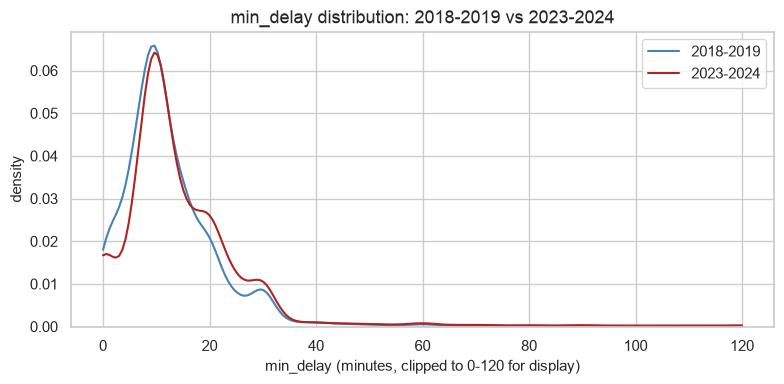

In [17]:
early = df[df["year"].isin([2018, 2019])]
late = df[df["year"].isin([2023, 2024])]

FINDINGS["early_period_n"] = int(len(early))
FINDINGS["late_period_n"] = int(len(late))
FINDINGS["early_mean_delay"] = float(early["min_delay"].mean())
FINDINGS["late_mean_delay"] = float(late["min_delay"].mean())
FINDINGS["early_median_delay"] = float(early["min_delay"].median())
FINDINGS["late_median_delay"] = float(late["min_delay"].median())

print(f"2018-2019: n={FINDINGS['early_period_n']:,}, mean={FINDINGS['early_mean_delay']:.2f}, "
      f"median={FINDINGS['early_median_delay']:.2f}")
print(f"2023-2024: n={FINDINGS['late_period_n']:,}, mean={FINDINGS['late_mean_delay']:.2f}, "
      f"median={FINDINGS['late_median_delay']:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(early["min_delay"], clip=(0, 120), label="2018-2019", ax=ax, color="steelblue")
sns.kdeplot(late["min_delay"], clip=(0, 120), label="2023-2024", ax=ax, color="firebrick")
ax.set_xlabel("min_delay (minutes, clipped to 0-120 for display)")
ax.set_ylabel("density")
ax.set_title("min_delay distribution: 2018-2019 vs 2023-2024")
ax.legend()
fig.tight_layout()
save_fig(fig, "14_drift_delay_distribution.png")
plt.show()

                       2018-2019  2023-2024
incident                                   
MECHANICAL             32.691252   34.28962
OPERATIONS - OPERATOR        0.0   18.69918
GENERAL DELAY          17.379826   6.342711
UTILIZED OFF ROUTE     15.661173   4.295793
INVESTIGATION           11.74776   2.069847
DIVERSION               6.071318   6.574654
LATE LEAVING GARAGE      12.8835        0.0
SECURITY                     0.0   8.439016
saved reports/figures/15_drift_incident_mix.png


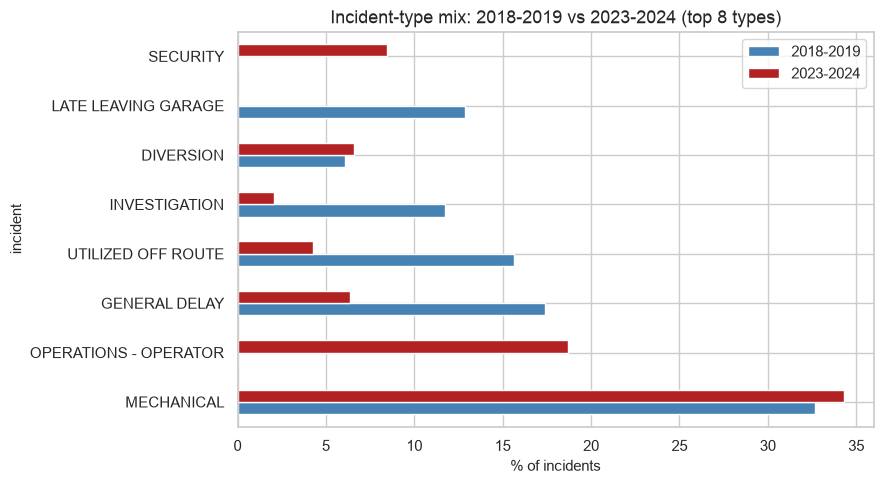

In [18]:
top_types = df["incident"].value_counts().head(8).index
early_mix = early["incident"].value_counts(normalize=True).reindex(top_types).fillna(0) * 100
late_mix = late["incident"].value_counts(normalize=True).reindex(top_types).fillna(0) * 100

mix = pd.DataFrame({"2018-2019": early_mix, "2023-2024": late_mix})
print(mix)

fig, ax = plt.subplots(figsize=(9, 5))
mix.plot.barh(ax=ax, color=["steelblue", "firebrick"])
ax.set_xlabel("% of incidents")
ax.set_title("Incident-type mix: 2018-2019 vs 2023-2024 (top 8 types)")
fig.tight_layout()
save_fig(fig, "15_drift_incident_mix.png")
plt.show()

FINDINGS["top_type_early_pct"] = float(early_mix.iloc[0])
FINDINGS["top_type_late_pct"] = float(late_mix.loc[early_mix.index[0]])
FINDINGS["top_type_for_drift"] = str(early_mix.index[0])

## Save computed numbers

Dump every number collected in `FINDINGS` to JSON so `docs/eda_findings.md`
is written from real, reproducible values rather than re-typed by hand.

In [19]:
out_path = PROJECT_ROOT / "reports" / "eda_findings.json"
out_path.write_text(json.dumps(FINDINGS, indent=2, default=str))
print(f"wrote {out_path.relative_to(PROJECT_ROOT)}")
FINDINGS

wrote reports/eda_findings.json


{'n_rows': 382131,
 'n_cols': 16,
 'date_min': '2018-01-01 00:17:00-05:00',
 'date_max': '2024-12-31 23:39:00-05:00',
 'n_routes': 480,
 'n_locations': 58640,
 'n_incident_types': 34,
 'n_vehicles': 3998,
 'missing_location_pct': 0.08,
 'missing_incident_pct': 0.24,
 'missing_min_gap_pct': 0.14,
 'missing_vehicle_pct': 6.76,
 'delay_median': 10.0,
 'delay_p75': 18.0,
 'delay_p90': 28.0,
 'delay_p95': 30.0,
 'delay_p99': 137.0,
 'delay_mean': 16.221800900738227,
 'zero_delay_pct': 4.6732664976146925,
 'peak_incident_hour': 15,
 'peak_delay_hour': 2,
 'peak_delay_hour_value': 26.99052446011459,
 'weekend_mean_delay': 17.81883363461002,
 'weekday_mean_delay': 15.78257213784267,
 'year_2020_count': 35633,
 'year_2019_count': 61471,
 'year_2020_drop_pct': 42.03282848823022,
 'year_2020_mean_delay': 15.795807257317655,
 'year_counts': {2018: 72417,
  2019: 61471,
  2020: 35633,
  2021: 41645,
  2022: 57575,
  2023: 55070,
  2024: 58320},
 'top_incident_by_count': 'MECHANICAL',
 'top_incident